# Tugas - Clustering dengan K-Means dan Hierarchical Clustering

| Nama | NRP |
|------|-----|
| Rakha Makarim | 5054251010 |

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model clustering menggunakan K-Means dan Hierarchical Clustering untuk mengelompokkan posting Facebook penjual berdasarkan pola engagement-nya (like, komentar, share, dan reaksi emoji).

Dataset yang digunakan: `Live.csv` (Facebook Live Sellers in Thailand, UCI). Setiap baris adalah satu posting Facebook dari penjual fashion dan kosmetik di Thailand.

Tujuan utama dari tugas ini adalah memahami cara kerja algoritma clustering secara praktik, khususnya:
1. Penentuan jumlah cluster yang optimal (Elbow Method dan Silhouette Score) serta pengaruh transformasi log dan feature scaling pada K-Means
2. Perbedaan metode linkage dan pembacaan dendrogram pada Hierarchical Clustering
3. Perbandingan hasil K-Means dan Hierarchical Clustering

**Catatan:** Kolom `status_type` TIDAK boleh digunakan sebagai fitur clustering. Kolom ini hanya dipakai untuk membantu menafsirkan cluster pada tahap evaluasi.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi fitur.
2. Preprocessing
   - Memproses data agar siap digunakan dalam clustering.
3. Eksperimen K-Means
   - Tentukan jumlah cluster dengan Elbow Method dan Silhouette Score, lalu bangun model K-Means.
4. Eksperimen Hierarchical Clustering
   - Amati dendrogram, bandingkan variasi linkage, lalu bangun model Agglomerative Clustering.
5. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
6. Analisis
7. Kesimpulan dan Saran

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, scipy, dll)

%matplotlib inline

import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn import metrics
from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_theme(style="whitegrid", context="notebook")

RANDOM_STATE = 42
N_INIT = 10


In [2]:
# Load dataset dan tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, jumlah missing value, dan jumlah baris duplikat.
# Perhatikan apakah ada kolom yang seluruhnya kosong.

candidates = [
    Path("../Data/Live.csv"),
    Path("Data/Live.csv"),
    Path("KMeans_Hierarchical Clustering/Data/Live.csv"),
]
DATA_PATH = next(p for p in candidates if p.exists())

df = pd.read_csv(DATA_PATH)

print("File dataset      :", DATA_PATH.resolve())
print("Jumlah baris, kolom:", df.shape)
print("\nTipe data tiap kolom:\n" + df.dtypes.to_string())
print("\nStatistik deskriptif:\n" + df.describe().T.to_string())
print("\nJumlah missing value per kolom:\n" + df.isna().sum().to_string())
print("\nJumlah baris duplikat (seluruh kolom):", int(df.duplicated().sum()))
empty_cols = [c for c in df.columns if df[c].isna().all()]
print("Kolom yang seluruhnya kosong:", empty_cols)


File dataset      : /home/makarim/Desktop/Collage/Machine Learning/Task_ML/KMeans_Hierarchical Clustering/Data/Live.csv
Jumlah baris, kolom: (7050, 16)

Tipe data tiap kolom:
status_id             int64
status_type             str
status_published        str
num_reactions         int64
num_comments          int64
num_shares            int64
num_likes             int64
num_loves             int64
num_wows              int64
num_hahas             int64
num_sads              int64
num_angrys            int64
Column1             float64
Column2             float64
Column3             float64
Column4             float64

Statistik deskriptif:
                count         mean          std  min      25%     50%      75%      max
status_id      7050.0  3525.500000  2035.304031  1.0  1763.25  3525.5  5287.75   7050.0
num_reactions  7050.0   230.117163   462.625309  0.0    17.00    59.5   219.00   4710.0
num_comments   7050.0   224.356028   889.636820  0.0     0.00     4.0    23.00  20990.0
nu

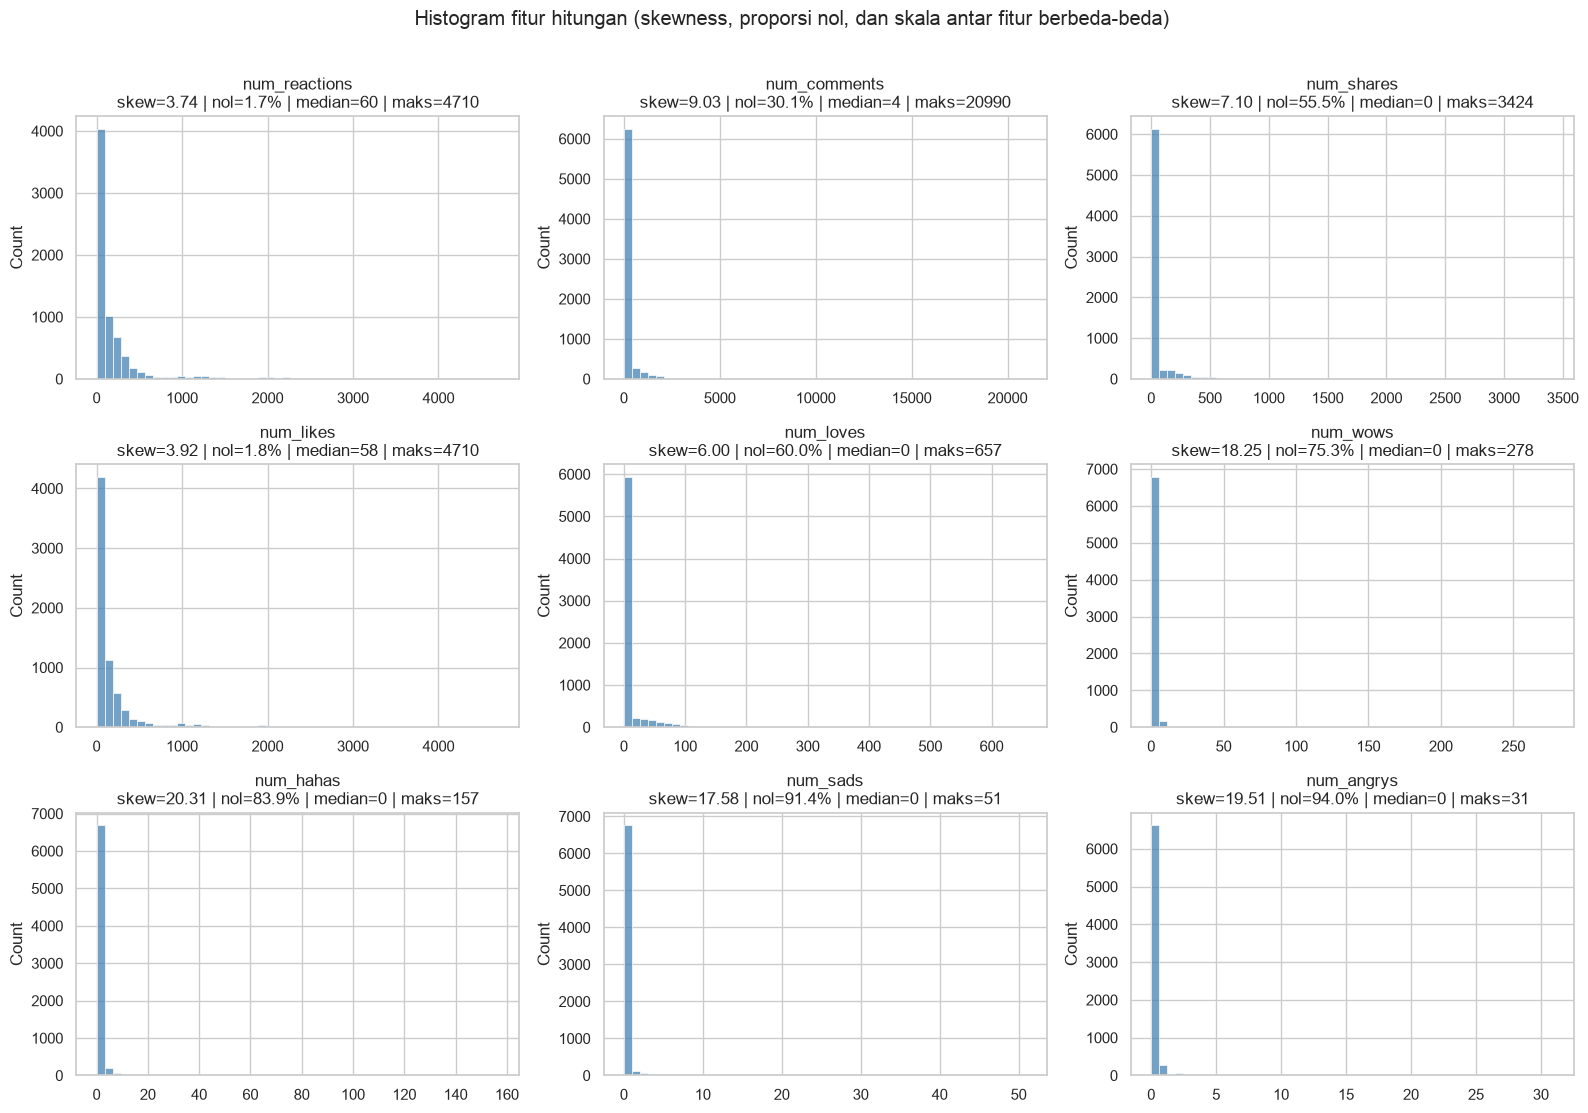

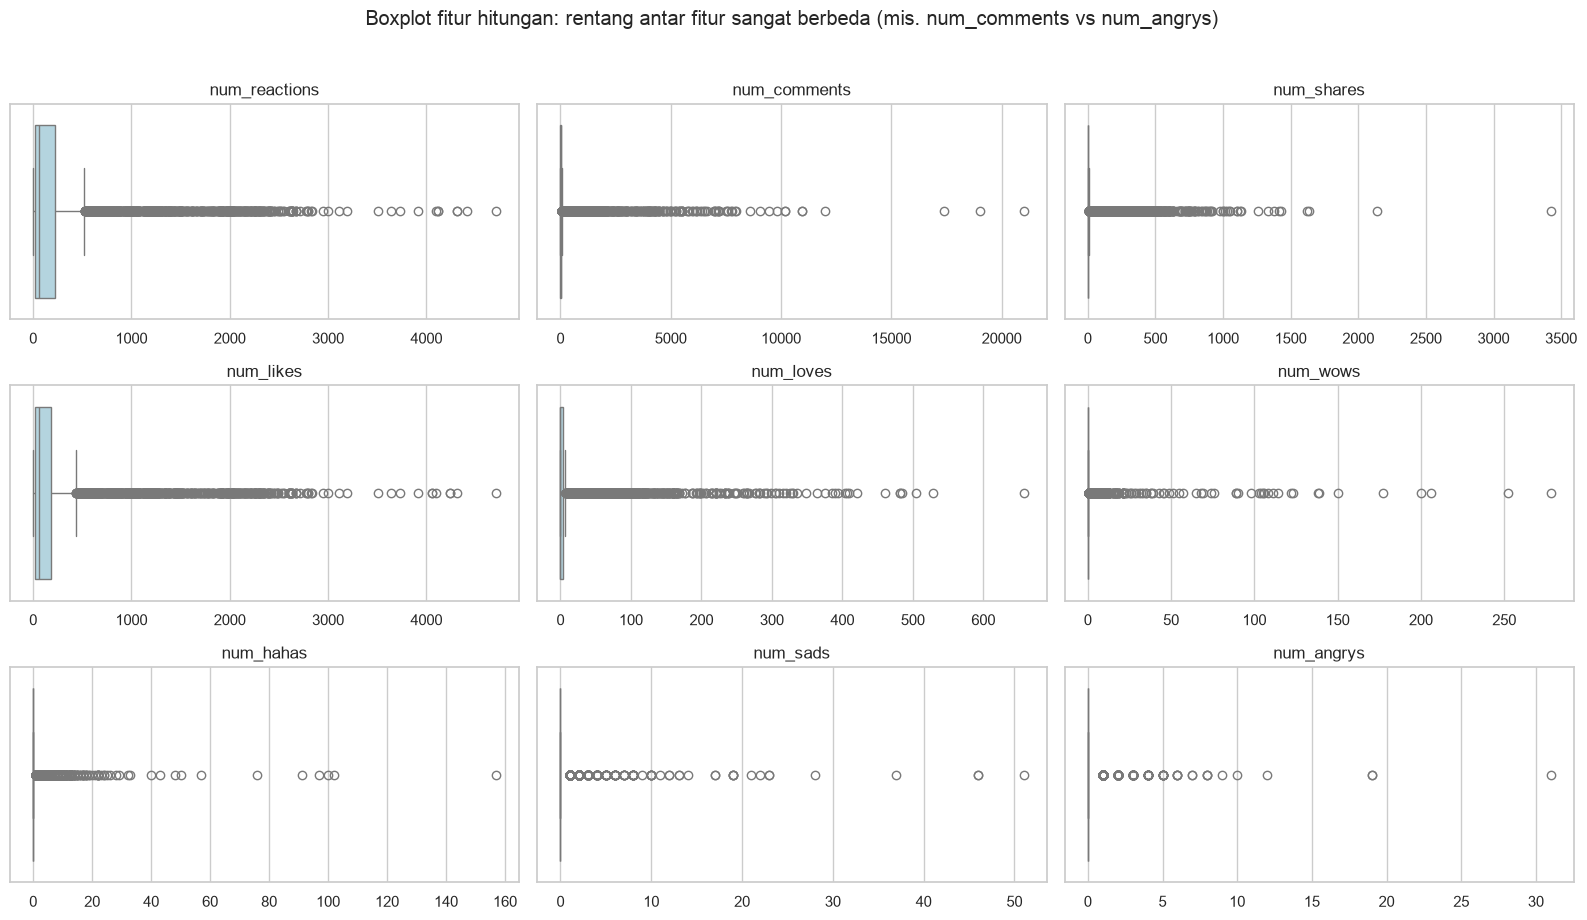

Rasio skala (std terbesar / std terkecil): 1224.0


In [3]:
# Tampilkan distribusi fitur hitungan (histogram atau boxplot).
# Perhatikan skewness, proporsi nilai nol, dan perbedaan skala antar fitur (misalnya num_comments vs num_angrys), karena ini penting untuk tahap preprocessing.

count_cols = ["num_reactions", "num_comments", "num_shares", "num_likes",
              "num_loves", "num_wows", "num_hahas", "num_sads", "num_angrys"]

fig, axes = plt.subplots(3, 3, figsize=(16, 11))
for ax, col in zip(axes.ravel(), count_cols):
    sns.histplot(df[col], bins=50, ax=ax, color="steelblue")
    ax.set_title(f"{col}\nskew={df[col].skew():.2f} | nol={100 * (df[col] == 0).mean():.1f}% | median={df[col].median():.0f} | maks={df[col].max():.0f}")
    ax.set_xlabel("")
plt.suptitle("Histogram fitur hitungan (skewness, proporsi nol, dan skala antar fitur berbeda-beda)", y=1.01)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 3, figsize=(16, 9))
for ax, col in zip(axes.ravel(), count_cols):
    sns.boxplot(x=df[col], ax=ax, color="lightblue")
    ax.set_title(col)
    ax.set_xlabel("")
plt.suptitle("Boxplot fitur hitungan: rentang antar fitur sangat berbeda (mis. num_comments vs num_angrys)", y=1.02)
plt.tight_layout()
plt.show()

print("Rasio skala (std terbesar / std terkecil):",
      round(df[count_cols].std().max() / df[count_cols].std().min(), 1))


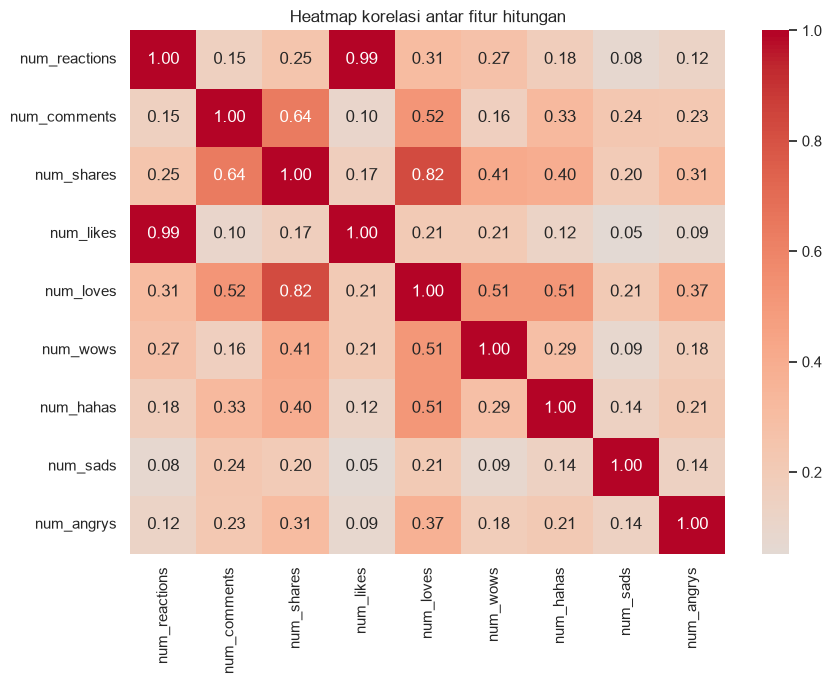

Korelasi tertinggi (di luar diagonal):
num_reactions  num_likes     0.995
num_shares     num_loves     0.820
num_comments   num_shares    0.641
               num_loves     0.521
num_loves      num_wows      0.509
               num_hahas     0.508


In [4]:
# Tampilkan heatmap korelasi antar fitur hitungan.
# Perhatikan fitur-fitur yang berkorelasi sangat tinggi atau saling berkaitan secara definisi (redundan), karena memengaruhi perhitungan jarak pada clustering.

plt.figure(figsize=(9, 7))
sns.heatmap(df[count_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Heatmap korelasi antar fitur hitungan")
plt.tight_layout()
plt.show()

print("Korelasi tertinggi (di luar diagonal):")
corr = df[count_cols].corr().abs()
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().sort_values(ascending=False)
print(pairs.head(6).round(3).to_string())


Jumlah posting dan proporsi posting dengan reaksi emoji per tahun:
      jumlah_posting  proporsi_emoji
year                                
2012             589             0.0
2013             500             0.0
2014             233             0.0
2015             337             0.0
2016             588            68.0
2017            2253            54.2
2018            2550            57.8


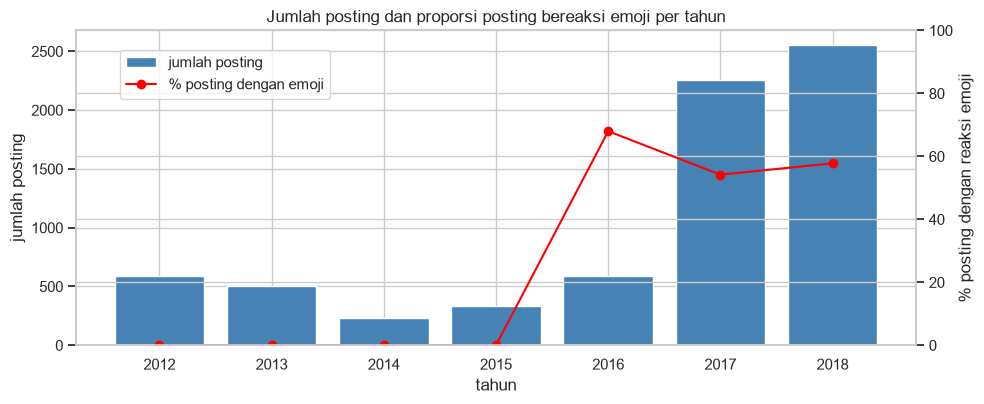

In [5]:
# Ubah kolom status_published menjadi datetime.
# Tampilkan jumlah posting dan proporsi posting yang memiliki reaksi emoji pada setiap tahun.
# Amati apakah ada perubahan pola dari tahun ke tahun.

df["status_published"] = pd.to_datetime(df["status_published"], format="mixed")

emoji_cols = ["num_loves", "num_wows", "num_hahas", "num_sads", "num_angrys"]
df["has_emoji"] = df[emoji_cols].sum(axis=1) > 0
df["year"] = df["status_published"].dt.year

tahun = df.groupby("year").agg(jumlah_posting=("status_id", "size"),
                               proporsi_emoji=("has_emoji", "mean"))
tahun["proporsi_emoji"] = (tahun["proporsi_emoji"] * 100).round(1)
print("Jumlah posting dan proporsi posting dengan reaksi emoji per tahun:")
print(tahun.to_string())

fig, ax1 = plt.subplots(figsize=(10, 4.2))
ax1.bar(tahun.index.astype(str), tahun["jumlah_posting"], color="steelblue", label="jumlah posting")
ax1.set_xlabel("tahun")
ax1.set_ylabel("jumlah posting")
ax2 = ax1.twinx()
ax2.plot(tahun.index.astype(str), tahun["proporsi_emoji"], color="red", marker="o", label="% posting dengan emoji")
ax2.set_ylabel("% posting dengan reaksi emoji")
ax2.set_ylim(0, 100)
plt.title("Jumlah posting dan proporsi posting bereaksi emoji per tahun")
fig.legend(loc="upper left", bbox_to_anchor=(0.12, 0.88))
plt.tight_layout()
plt.show()


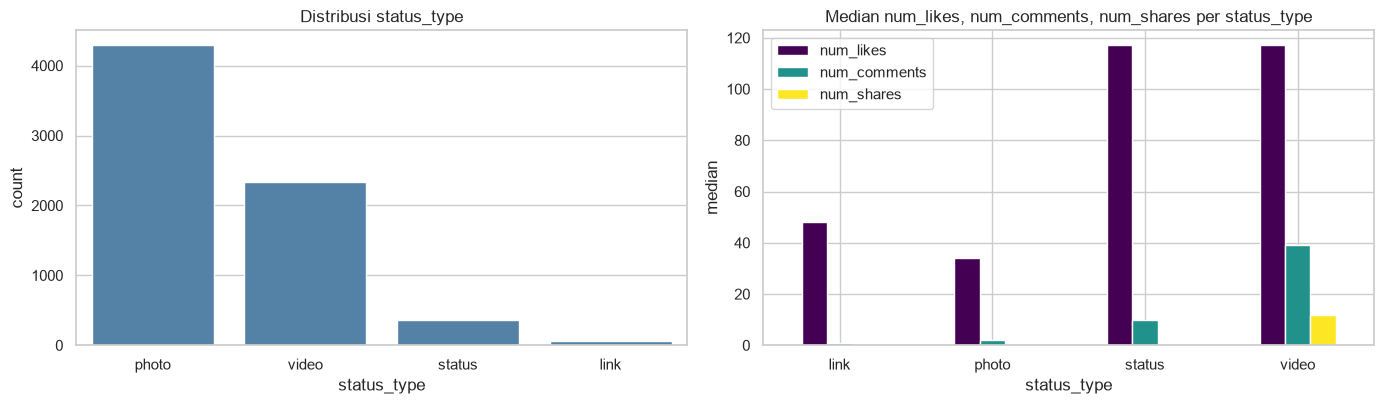

Median per status_type:
             num_likes  num_comments  num_shares
status_type                                     
link              48.0           1.0         0.0
photo             34.0           2.0         0.0
status           117.0          10.0         0.0
video            117.0          39.0        12.0


In [6]:
# Tampilkan distribusi status_type dalam bentuk bar plot.
# Bandingkan median num_likes, num_comments, dan num_shares untuk setiap status_type.

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
order = df["status_type"].value_counts().index
sns.countplot(data=df, x="status_type", order=order, ax=axes[0], color="steelblue")
axes[0].set_title("Distribusi status_type")

med = df.groupby("status_type")[["num_likes", "num_comments", "num_shares"]].median()
med.plot(kind="bar", ax=axes[1], colormap="viridis")
axes[1].set_title("Median num_likes, num_comments, num_shares per status_type")
axes[1].set_ylabel("median")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(title="")
plt.tight_layout()
plt.show()

print("Median per status_type:")
print(med.to_string())


## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

In [7]:
# EDA tambahan: besaran zero-inflation tiap fitur dan posting dengan engagement ekstrem,
# keduanya menjadi dasar keputusan preprocessing (penanganan fitur sparse dan outlier).

zero_prop = (df[count_cols] == 0).mean().sort_values(ascending=False) * 100
print("Proporsi nilai nol per fitur (%):")
print(zero_prop.round(1).to_string())
print("\nJumlah posting yang seluruh reaksi emoji-nya nol:",
      int((df[emoji_cols].sum(axis=1) == 0).sum()), "dari", len(df))

print("\n10 posting dengan num_reactions terbesar:")
print(df.nlargest(10, "num_reactions")[
    ["status_id", "status_type", "status_published", "num_reactions",
     "num_comments", "num_shares", "num_likes"]].to_string(index=False))

print("\nDeteksi outlier ekstrem (batas kuartil 3 + 1.5 * IQR):")
for c in ["num_reactions", "num_comments", "num_shares", "num_likes"]:
    q1, q3 = df[c].quantile([0.25, 0.75])
    fence = q3 + 1.5 * (q3 - q1)
    print(f"  {c:14s}: fence={fence:7.0f} | di atas fence={int((df[c] > fence).sum()):5d} "
          f"| maksimum={int(df[c].max()):6d} | rasio maks/median={df[c].max() / max(df[c].median(), 1):.0f}x")


Proporsi nilai nol per fitur (%):
num_angrys       94.0
num_sads         91.4
num_hahas        83.9
num_wows         75.3
num_loves        60.0
num_shares       55.5
num_comments     30.1
num_likes         1.8
num_reactions     1.7

Jumlah posting yang seluruh reaksi emoji-nya nol: 3956 dari 7050

10 posting dengan num_reactions terbesar:
 status_id status_type    status_published  num_reactions  num_comments  num_shares  num_likes
      1230       photo 2015-04-10 06:31:00           4710            50           1       4710
       167       photo 2017-09-03 05:39:00           4410           633         257       4315
      6198       photo 2018-04-11 03:43:00           4315            24           3       4241
      6249       photo 2018-04-11 03:43:00           4315            24           3       4241
      6199       photo 2018-04-09 10:49:00           4114           104           3       4054
      6250       photo 2018-04-09 10:49:00           4114           104           3      

# 2. Preprocessing

In [8]:
# Hapus kolom yang seluruhnya kosong.
# Periksa dan tangani baris duplikat (ingat bahwa status_id selalu unik untuk tiap baris).
# Periksa juga missing value dan outlier ekstrem, lalu tentukan penanganannya.

# 1) Kolom yang seluruhnya kosong
empty_cols = [c for c in df.columns if df[c].isna().all()]
df = df.drop(columns=empty_cols)
print("Kolom seluruhnya kosong yang dihapus:", empty_cols)

# 2) Baris duplikat: status_id selalu unik, jadi duplikasi dilihat dari isi barisnya
key_cols = [c for c in df.columns if c != "status_id"]
dup_mask = df.duplicated(subset=key_cols, keep="first")
print("Baris duplikat (diabaikan status_id):", int(dup_mask.sum()))
df = df[~dup_mask].reset_index(drop=True)
print("Sisa baris setelah duplikat dihapus:", len(df))

# 3) Missing value
print("Total missing value:", int(df.isna().sum().sum()))

# 4) Outlier ekstrem
rows = {}
for c in count_cols:
    q1, q3 = df[c].quantile([0.25, 0.75])
    fence = q3 + 1.5 * (q3 - q1)
    rows[c] = {"fence": round(fence), "n_outlier": int((df[c] > fence).sum()),
               "maksimum": int(df[c].max()), "nol_%": round(100 * (df[c] == 0).mean(), 1)}
outlier_info = pd.DataFrame(rows).T
print("\nRingkasan outlier dan zero-inflation:")
print(outlier_info.to_string())

print("\nKeputusan penanganan:")
print("- Missing value : tidak ada, kolom kosong (Column1-Column4) sudah dihapus.")
print("- Duplikat      : 54 baris isi sama persis dihapus (status_id tetap unik per baris).")
print("- Outlier       : TIDAK dibuang. Posting viral adalah bagian dari pola engagement yang")
print("                  ingin di-cluster; pengaruhnya dikendalikan lewat transformasi log1p + scaling.")


Kolom seluruhnya kosong yang dihapus: ['Column1', 'Column2', 'Column3', 'Column4']
Baris duplikat (diabaikan status_id): 54
Sisa baris setelah duplikat dihapus: 6996
Total missing value: 0

Ringkasan outlier dan zero-inflation:
               fence  n_outlier  maksimum  nol_%
num_reactions  514.0      689.0    4710.0    1.7
num_comments    56.0     1365.0   20990.0   30.2
num_shares      10.0     1382.0    3424.0   55.8
num_likes      430.0      754.0    4710.0    1.8
num_loves        8.0     1303.0     657.0   60.4
num_wows         0.0     1702.0     278.0   75.7
num_hahas        0.0     1117.0     157.0   84.0
num_sads         0.0      598.0      51.0   91.5
num_angrys       0.0      420.0      31.0   94.0

Keputusan penanganan:
- Missing value : tidak ada, kolom kosong (Column1-Column4) sudah dihapus.
- Duplikat      : 54 baris isi sama persis dihapus (status_id tetap unik per baris).
- Outlier       : TIDAK dibuang. Posting viral adalah bagian dari pola engagement yang
            

In [9]:
# Pisahkan status_type dan status_published (untuk interpretasi cluster pada tahap evaluasi) dari fitur yang akan dipakai untuk clustering.
# Hapus kolom yang tidak relevan untuk clustering (misalnya status_id).
# Periksa apakah ada fitur yang redundan (misalnya fitur yang merupakan penjumlahan fitur lain) atau yang sebagian besar bernilai nol.
# Pilih fitur yang akan dipakai untuk clustering. Pertimbangkan untuk menggabungkan fitur yang sparse.
# Catatan: K-Means dan Hierarchical Clustering berbasis jarak, sehingga semua fitur harus berupa angka.

# Kolom yang hanya untuk interpretasi cluster pada tahap evaluasi
df_meta = df[["status_id", "status_type", "status_published"]].copy()

# Kolom yang tidak relevan untuk clustering
df_feat = df.drop(columns=["status_id", "status_type", "status_published", "year", "has_emoji"])

# Cek fitur redundan: num_reactions hampir tepat jumlah seluruh komponennya
emoji_cols = ["num_loves", "num_wows", "num_hahas", "num_sads", "num_angrys"]
jumlah_komponen = df_feat["num_likes"] + df_feat[emoji_cols].sum(axis=1)
print("Selisih maks |num_reactions - (num_likes + emoji)|:", int((df_feat["num_reactions"] - jumlah_komponen).abs().max()))
print("Korelasi num_reactions vs num_likes:", round(df_feat["num_reactions"].corr(df_feat["num_likes"]), 3))

# Gabungkan fitur emoji yang sparse menjadi satu
df_feat["num_emoji_reactions"] = df_feat[emoji_cols].sum(axis=1)
df_feat = df_feat.drop(columns=["num_reactions"] + emoji_cols)

features = ["num_likes", "num_comments", "num_shares", "num_emoji_reactions"]
df_feat = df_feat[features]

print("\nProporsi nilai nol tiap fitur terpilih (%):")
print((100 * (df_feat == 0).mean()).round(1).to_string())
print("\nBentuk matriks fitur:", df_feat.shape)
print("\n5 baris pertama fitur:")
print(df_feat.head().to_string())


Selisih maks |num_reactions - (num_likes + emoji)|: 4
Korelasi num_reactions vs num_likes: 0.995

Proporsi nilai nol tiap fitur terpilih (%):
num_likes               1.8
num_comments           30.2
num_shares             55.8
num_emoji_reactions    56.5

Bentuk matriks fitur: (6996, 4)

5 baris pertama fitur:
   num_likes  num_comments  num_shares  num_emoji_reactions
0        432           512         262                   97
1        150             0           0                    0
2        204           236          57                   23
3        111             0           0                    0
4        204             0           0                    9


**Fitur yang dipilih untuk clustering:** `num_likes`, `num_comments`, `num_shares`, dan `num_emoji_reactions` (4 fitur, seluruhnya numerik).

Keputusan terhadap kolom yang redundan atau banyak bernilai nol:

- **`status_id`** - hanya identifier yang selalu unik tiap baris, tidak mencerminkan engagement -> **dihapus**.
- **`num_reactions`** - **redundan**, hampir tepat sama dengan jumlah komponennya sendiri (`num_likes` + seluruh reaksi emoji): selisih maksimum hanya 4 dan korelasinya 0,995 dengan `num_likes` (heatmap korelasi juga memperlihatkan hal ini). Memakainya berarti menimbang "like" dua kali -> **dibuang**.
- **`num_loves`, `num_wows`, `num_hahas`, `num_sads`, `num_angrys`** - sangat sparse (60% sampai 94% bernilai nol; 3.956 dari 7.050 posting sama sekali tidak punya reaksi emoji, karena fitur emoji baru ada di Facebook sejak tahun 2016: proporsi 0% pada 2012-2015 dan 54-68% pada 2016-2018). Kelima kolom **digabung menjadi satu fitur `num_emoji_reactions`** (penjumlahan kelimanya) agar perhitungan jarak tidak didominasi kolom yang hampir selalu nol, sekaligus tetap mewakili "reaksi emoji" sesuai deskripsi tugas.
- **`status_type` dan `status_published`** - disisihkan ke `df_meta` **hanya untuk menafsirkan cluster pada tahap evaluasi**; `status_type` tidak dipakai sebagai fitur clustering sesuai aturan tugas.
- **`Column1`-`Column4`** - seluruhnya kosong (7.050 missing value) -> dihapus pada tahap preprocessing.
- Nilai **0 bukan missing value**, melainkan "tidak ada engagement" (mis. `num_shares` 55,8% nol), sehingga dibiarkan apa adanya.
- **Outlier ekstrem dipertahankan** (tidak dibuang): mis. `num_comments` mencapai 20.990 padahal batas IQR hanya 58 (1.365 baris di atasnya). Posting viral justru bagian dari pola engagement yang ingin di-cluster; pengaruhnya dikendalikan lewat transformasi `log1p` + scaling, bukan dengan membuang data.
- Keempat fitur terpilih persis mewakili definisi tugas: **like, komentar, share, dan reaksi emoji**.



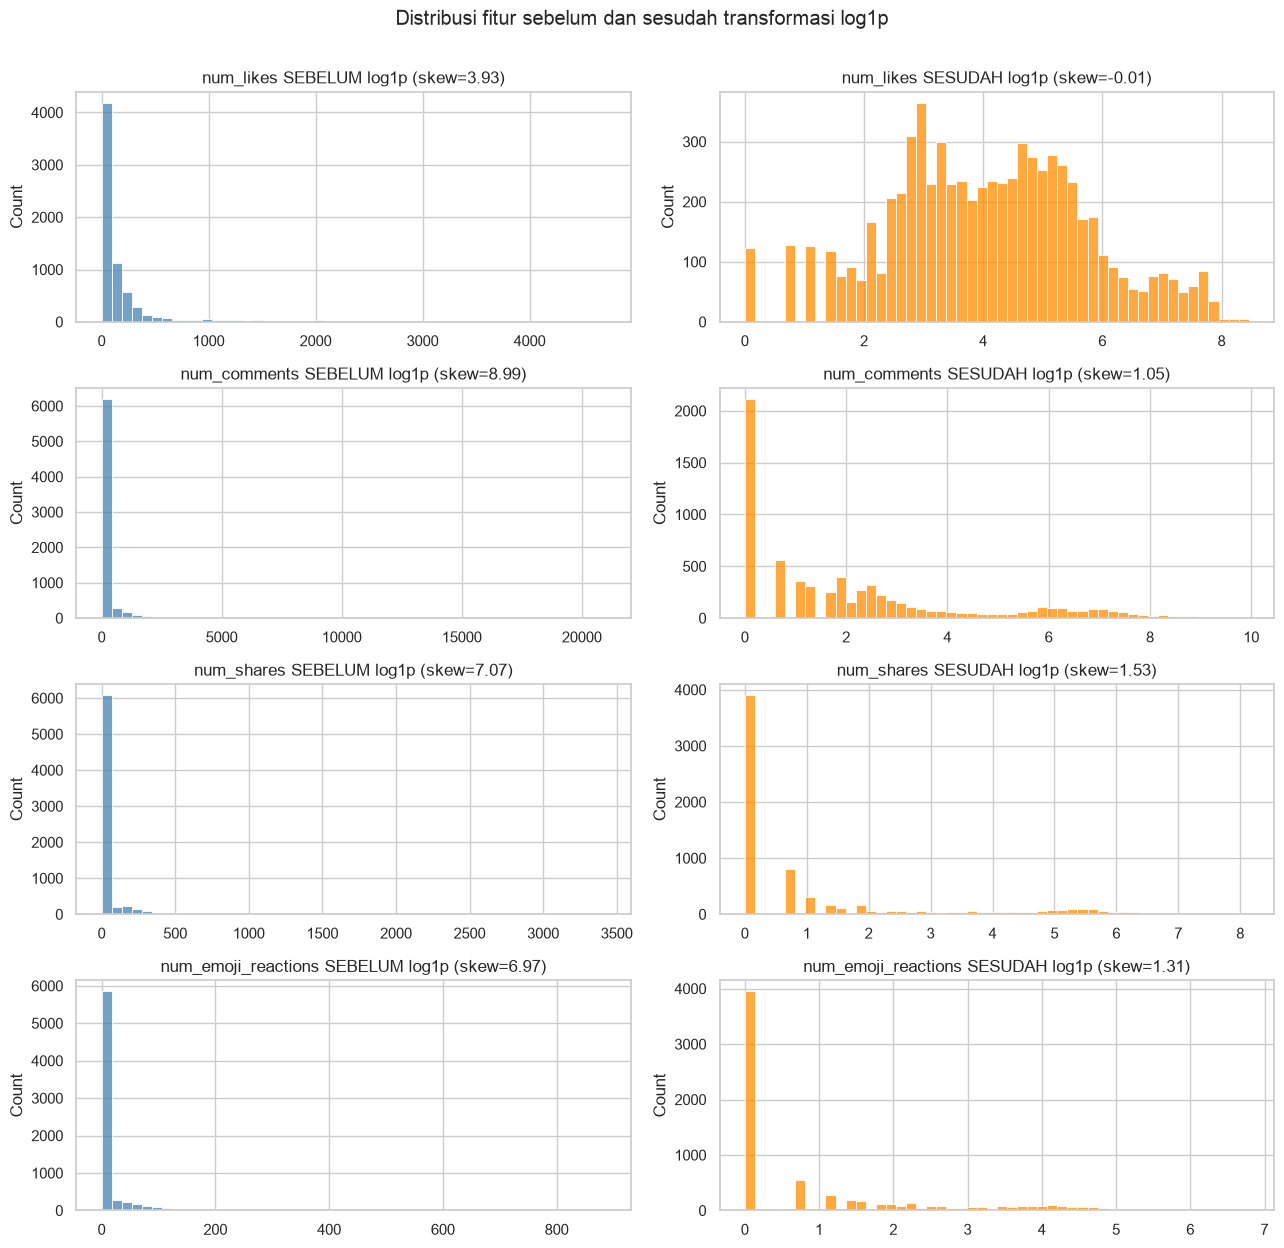

Skewness sebelum -> sesudah log1p:
                     sebelum  sesudah
num_likes               3.93    -0.01
num_comments            8.99     1.05
num_shares              7.07     1.53
num_emoji_reactions     6.97     1.31


In [10]:
# Fitur hitungan pada dataset ini sangat miring (skewed). Terapkan transformasi log1p pada fitur yang dipilih.
# Tampilkan distribusi fitur sebelum dan sesudah transformasi untuk melihat perbedaannya.

X_log = np.log1p(df_feat)

fig, axes = plt.subplots(len(features), 2, figsize=(13, 3.1 * len(features)))
for i, col in enumerate(features):
    sns.histplot(df_feat[col], bins=50, ax=axes[i, 0], color="steelblue")
    axes[i, 0].set_title(f"{col} SEBELUM log1p (skew={df_feat[col].skew():.2f})")
    axes[i, 0].set_xlabel("")
    sns.histplot(X_log[col], bins=50, ax=axes[i, 1], color="darkorange")
    axes[i, 1].set_title(f"{col} SESUDAH log1p (skew={X_log[col].skew():.2f})")
    axes[i, 1].set_xlabel("")
plt.suptitle("Distribusi fitur sebelum dan sesudah transformasi log1p", y=1.005)
plt.tight_layout()
plt.show()

print("Skewness sebelum -> sesudah log1p:")
print(pd.DataFrame({"sebelum": df_feat.skew().round(2), "sesudah": X_log.skew().round(2)}).to_string())


In [11]:
# Lakukan feature scaling (misalnya StandardScaler) pada fitur hasil transformasi log dan simpan hasilnya (X_log_scaled).
# Simpan juga versi lain untuk keperluan perbandingan pada bagian 3.1:
# - X_raw: fitur mentah tanpa transformasi dan tanpa scaling
# - X_raw_scaled: fitur mentah dengan scaling saja

# X_log_scaled : fitur hasil log1p + StandardScaler  -> dipakai untuk semua model
# X_raw        : fitur mentah tanpa transformasi dan tanpa scaling
# X_raw_scaled : fitur mentah dengan scaling saja    -> untuk perbandingan pada bagian 3.1
X_raw = df_feat.values.astype(float)
X_log = np.log1p(df_feat)

X_log_scaled = StandardScaler().fit_transform(X_log)
X_raw_scaled = StandardScaler().fit_transform(X_raw)

print("Bentuk: X_raw", X_raw.shape, "| X_raw_scaled", X_raw_scaled.shape, "| X_log_scaled", X_log_scaled.shape)
print("\nRata-rata dan std per fitur pada X_log_scaled (seharusnya ~0 dan ~1):")
print(pd.DataFrame(X_log_scaled, columns=features).agg(["mean", "std"]).round(3).to_string())


Bentuk: X_raw (6996, 4) | X_raw_scaled (6996, 4) | X_log_scaled (6996, 4)

Rata-rata dan std per fitur pada X_log_scaled (seharusnya ~0 dan ~1):
      num_likes  num_comments  num_shares  num_emoji_reactions
mean       -0.0          -0.0         0.0                 -0.0
std         1.0           1.0         1.0                  1.0


# 3. Eksperimen K-Means

## 3.1 Pengaruh Transformasi Log dan Feature Scaling pada K-Means

K-Means mengelompokkan data dengan meminimalkan jarak antara titik dan centroid cluster. Pada bagian ini kalian akan mengamati bagaimana transformasi log dan scaling memengaruhi hasil clustering.

In [12]:
# Latih K-Means dengan jumlah cluster yang sama (misalnya k=3) pada tiga versi data:
# (1) X_raw (mentah tanpa scaling), (2) X_raw_scaled (mentah dengan scaling), dan (3) X_log_scaled (log dan scaling).
# Gunakan random_state dan n_init yang sama agar perbandingan adil.

versi = {
    "X_raw (mentah, tanpa scaling)": X_raw,
    "X_raw_scaled (mentah + scaling)": X_raw_scaled,
    "X_log_scaled (log + scaling)": X_log_scaled,
}

km_versions = {}
for nama, X in versi.items():
    km = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=N_INIT)
    km_versions[nama] = km.fit(X)
print("Model K-Means k=3 selesai dilatih untuk", len(km_versions), "versi data")


Model K-Means k=3 selesai dilatih untuk 3 versi data


In [13]:
# Bandingkan ketiga hasil tersebut: jumlah anggota tiap cluster dan Silhouette Score.
# Hitung Silhouette ketiganya pada ruang yang sama (misalnya X_log_scaled) agar perbandingannya adil.
# Amati fitur mana yang mendominasi varians pada data tanpa scaling, dan apakah ada cluster yang sangat kecil atau sangat besar.

baris = []
for nama, km in km_versions.items():
    labels = km.labels_
    ukuran = np.bincount(labels)
    sil = metrics.silhouette_samples(X_log_scaled, labels).mean()
    baris.append({
        "versi data": nama,
        "ukuran cluster": " / ".join(str(u) for u in ukuran),
        "cluster terkecil": int(ukuran.min()),
        "cluster terbesar": int(ukuran.max()),
        "Silhouette (pada X_log_scaled)": round(sil, 4),
    })
print(pd.DataFrame(baris).to_string(index=False))

var_raw = X_raw.var(axis=0)
print("\nVarians per fitur pada X_raw (tanpa scaling):")
print(pd.DataFrame({"varians": var_raw,
                    "% varians total": (100 * var_raw / var_raw.sum()).round(1)}, index=features).to_string())
print("Rasio std terbesar/terkecil pada X_raw:",
      round(X_raw.std(axis=0).max() / X_raw.std(axis=0).min(), 1), "kali")
print("Std per fitur pada X_raw:", dict(zip(features, X_raw.std(axis=0).round(1))))


                     versi data     ukuran cluster  cluster terkecil  cluster terbesar  Silhouette (pada X_log_scaled)
  X_raw (mentah, tanpa scaling)   6392 / 137 / 467               137              6392                          0.2731
X_raw_scaled (mentah + scaling)   373 / 6277 / 346               346              6277                          0.2533
   X_log_scaled (log + scaling) 1131 / 2258 / 3607              1131              3607                          0.4638

Varians per fitur pada X_raw (tanpa scaling):
                           varians  % varians total
num_likes            193240.815832             19.1
num_comments         797196.098928             78.9
num_shares            17440.674038              1.7
num_emoji_reactions    2299.243621              0.2
Rasio std terbesar/terkecil pada X_raw: 18.6 kali
Std per fitur pada X_raw: {'num_likes': np.float64(439.6), 'num_comments': np.float64(892.9), 'num_shares': np.float64(132.1), 'num_emoji_reactions': np.float64(48.0)}

## 3.2 Menentukan Jumlah Cluster dengan Elbow Method

Elbow Method memplot nilai inertia (Within-Cluster Sum of Squares) terhadap jumlah cluster k. Titik "siku" pada grafik menunjukkan nilai k setelah mana penambahan cluster tidak lagi memberikan penurunan inertia yang berarti.

In [14]:
# Latih K-Means pada X_log_scaled untuk rentang k tertentu (misalnya k = 2 sampai 10).
# Simpan nilai inertia untuk setiap k.

k_range = range(2, 11)
inertias = {}
for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=N_INIT)
    km.fit(X_log_scaled)
    inertias[k] = km.inertia_

elbow_df = pd.DataFrame({"k": list(inertias.keys()), "inertia": list(inertias.values())})
elbow_df["penurunan_%"] = (-elbow_df["inertia"].pct_change() * 100).round(1)
print(elbow_df.to_string(index=False))


 k      inertia  penurunan_%
 2 11586.902228          NaN
 3  6779.837072         41.5
 4  5678.250880         16.2
 5  4739.956456         16.5
 6  4220.276309         11.0
 7  3772.102448         10.6
 8  3418.565715          9.4
 9  3116.428087          8.8
10  2899.054919          7.0


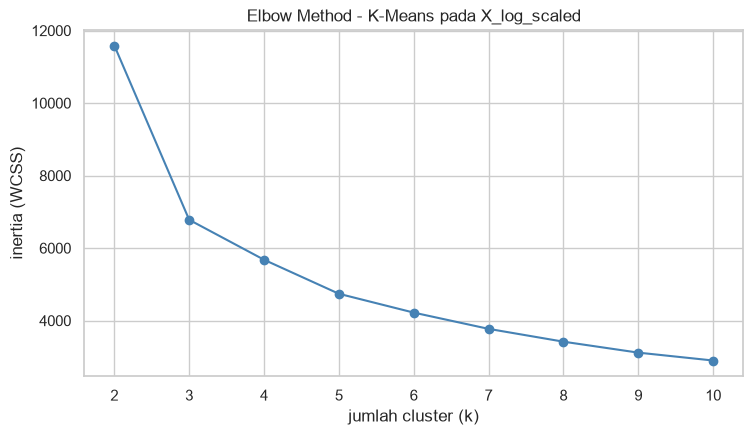

Elbow terdeteksi otomatis (KneeLocator): k = 4
Pengamatan manual: penurunan inertia paling tajam terjadi pada k=2 -> k=3,
lalu melandai; KneeLocator menandai siku di k = 4


In [15]:
# Plot grafik Elbow (k vs inertia).
# Amati pada nilai k berapa terbentuk "siku".
# (Opsional) Gunakan library kneed (KneeLocator) untuk mendeteksi elbow secara otomatis, lalu bandingkan dengan pengamatan kalian.

plt.figure(figsize=(8.5, 4.5))
plt.plot(list(inertias.keys()), list(inertias.values()), marker="o", color="steelblue")
plt.xticks(list(inertias.keys()))
plt.xlabel("jumlah cluster (k)")
plt.ylabel("inertia (WCSS)")
plt.title("Elbow Method - K-Means pada X_log_scaled")
plt.show()

knee_k = None
try:
    from kneed import KneeLocator
    kn = KneeLocator(list(inertias.keys()), list(inertias.values()),
                     curve="convex", direction="decreasing")
    knee_k = kn.knee
    print("Elbow terdeteksi otomatis (KneeLocator): k =", knee_k)
except Exception as e:
    print("KneeLocator tidak tersedia:", e)

print("Pengamatan manual: penurunan inertia paling tajam terjadi pada k=2 -> k=3,")
print("lalu melandai; KneeLocator menandai siku di k =", knee_k)


## 3.3 Menentukan Jumlah Cluster dengan Silhouette Score

Silhouette Score mengukur seberapa mirip sebuah titik dengan clusternya sendiri dibandingkan dengan cluster lain. Nilainya berkisar dari -1 sampai 1, semakin tinggi semakin baik.

In [16]:
# Hitung Silhouette Score untuk setiap nilai k pada rentang yang sama dengan Elbow Method.
# Simpan hasilnya dalam list atau dictionary agar mudah diplot.

sil_scores = {}
for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=N_INIT)
    labels = km.fit_predict(X_log_scaled)
    sil_scores[k] = metrics.silhouette_score(X_log_scaled, labels)

sil_df = pd.DataFrame({"k": list(sil_scores.keys()), "silhouette": list(sil_scores.values())})
sil_df["silhouette"] = sil_df["silhouette"].round(4)
print(sil_df.to_string(index=False))

best_k_sil = max(sil_scores, key=sil_scores.get)
print("\nSilhouette tertinggi: k =", best_k_sil, "->", round(sil_scores[best_k_sil], 4))


 k  silhouette
 2      0.5899
 3      0.4638
 4      0.3372
 5      0.3586
 6      0.3469
 7      0.3367
 8      0.3154
 9      0.3293
10      0.3160

Silhouette tertinggi: k = 2 -> 0.5899


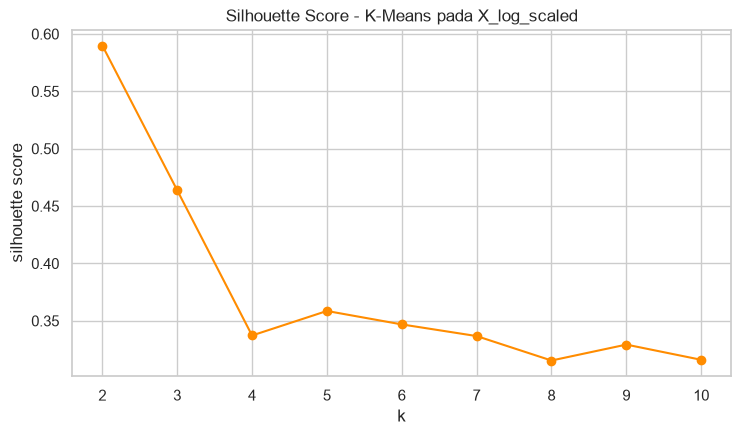

Silhouette terbaik : k = 2 ( 0.5899 )
Elbow (KneeLocator): k = 4
Inertia terbesar menurun saat k 2 -> 3, tetapi silhouette justru memuncak di k = 2


In [17]:
# Plot grafik Silhouette Score terhadap k.
# Tentukan nilai k terbaik dengan mempertimbangkan hasil Elbow Method dan Silhouette Score, lalu jelaskan alasannya pada cell markdown di bawah.

plt.figure(figsize=(8.5, 4.5))
plt.plot(list(sil_scores.keys()), list(sil_scores.values()), marker="o", color="darkorange")
plt.xticks(list(sil_scores.keys()))
plt.xlabel("k")
plt.ylabel("silhouette score")
plt.title("Silhouette Score - K-Means pada X_log_scaled")
plt.show()

best_k_sil = max(sil_scores, key=sil_scores.get)
print("Silhouette terbaik : k =", best_k_sil, "(", round(sil_scores[best_k_sil], 4), ")")
print("Elbow (KneeLocator): k =", knee_k)
print("Inertia terbesar menurun saat k 2 -> 3, tetapi silhouette justru memuncak di k =", best_k_sil)


**Pilihan k untuk K-Means:** **k = 2**

Alasan singkat:

- **Silhouette Score memuncak tegas pada k = 2 (0,5899)** dan tidak pernah terlampaui lagi pada rentang k = 2-10 (k=3: 0,4638; k=4: 0,3372; k=5: 0,3586; lalu berfluktuasi turun sampai 0,3160 pada k=10).
- **Elbow Method** menunjukkan penurunan inertia paling tajam pada k = 2 -> 3 (turun 41,5%, dari 11.586,9 ke 6.779,8), lalu melandai (16,2%; 16,5%; 11,0%; 10,6%; dst.), dan `KneeLocator` menandai siku di **k = 4**.
- Keduanya **berbeda**. Karena penambahan cluster setelah k = 2 justru **menurunkan** silhouette (tidak ada k > 2 yang lebih baik), maka yang dipilih adalah **k = 2**: pemisahan paling jelas, ukuran cluster tetap masuk akal dan relatif seimbang (5.618 vs 1.378), paling mudah diinterpretasikan (posting engagement rendah vs tinggi), serta sejalan dengan potongan dendrogram (celah tinggi penggabungan antara 103,70 dan 175,13) dan dengan hasil Hierarchical Clustering (silhouette linkage ward pada k = 2 = 0,5951, tertinggi di antara seluruh alternatif linkage yang diuji).



## 3.4 Model K-Means Final

In [18]:
# Latih model K-Means final dengan nilai k terbaik yang kalian pilih pada X_log_scaled.
# Simpan label cluster hasil prediksi untuk keperluan evaluasi.

K_FINAL = 2

km_final = KMeans(n_clusters=K_FINAL, random_state=RANDOM_STATE, n_init=N_INIT)
kmeans_labels = km_final.fit_predict(X_log_scaled)

print("K-Means final: k =", K_FINAL, "| random_state =", RANDOM_STATE, "| n_init =", N_INIT)
print("Inertia  :", round(km_final.inertia_, 2))
print("Silhouette pada X_log_scaled:", round(metrics.silhouette_score(X_log_scaled, kmeans_labels), 4))
print("Jumlah anggota tiap cluster:", np.bincount(kmeans_labels))
print("Centroid (ruang fitur ter-skalakan):")
print(pd.DataFrame(km_final.cluster_centers_, columns=features).round(3).to_string())


K-Means final: k = 2 | random_state = 42 | n_init = 10
Inertia  : 11586.9


Silhouette pada X_log_scaled: 0.5899
Jumlah anggota tiap cluster: [5618 1378]
Centroid (ruang fitur ter-skalakan):
   num_likes  num_comments  num_shares  num_emoji_reactions
0     -0.203        -0.416      -0.432               -0.416
1      0.827         1.698       1.763                1.698


In [19]:
# Buat profil setiap cluster pada data ASLI (sebelum transformasi log dan scaling): tampilkan median (dan rata-rata) tiap fitur per cluster beserta jumlah anggotanya.
# Gunakan median karena distribusi fitur sangat miring.
# Ini membantu menginterpretasikan karakteristik tiap cluster.

profile_km = df_feat.copy()
profile_km["cluster"] = kmeans_labels

print("Profil cluster K-Means pada data ASLI (skala counts, median):")
print(profile_km.groupby("cluster")[features].median().round(1).to_string())
print("\nRata-rata per fitur (sangat miring, jadi hanya pelengkap):")
print(profile_km.groupby("cluster")[features].mean().round(1).to_string())
print("\nJumlah anggota tiap cluster:")
print(profile_km.groupby("cluster").size().rename("jumlah").to_string())


Profil cluster K-Means pada data ASLI (skala counts, median):
         num_likes  num_comments  num_shares  num_emoji_reactions
cluster                                                          
0             33.0           2.0         0.0                  0.0
1            191.0         524.0       141.5                 48.0

Rata-rata per fitur (sangat miring, jadi hanya pelengkap):
         num_likes  num_comments  num_shares  num_emoji_reactions
cluster                                                          
0            168.8           7.2         1.3                  1.3
1            378.3        1116.4       199.0                 71.0

Jumlah anggota tiap cluster:
cluster
0    5618
1    1378


# 4. Eksperimen Hierarchical Clustering

## 4.1 Dendrogram

Hierarchical Clustering (Agglomerative) memulai dengan setiap titik sebagai cluster tersendiri, lalu menggabungkan dua cluster terdekat secara berulang hingga tersisa satu cluster. Dendrogram memvisualisasikan proses penggabungan tersebut.

In [20]:
# Hitung linkage matrix (scipy.cluster.hierarchy.linkage) dengan metode ward pada X_log_scaled.
# Dataset berisi sekitar 7.000 baris sehingga proses ini masih ringan dan tidak perlu dilakukan sampling.

Z = linkage(X_log_scaled, method="ward")
print("Bentuk linkage matrix:", Z.shape, "(n-1 baris, 4 kolom: [idx1, idx2, jarak, ukuran cluster])")
print("\n8 penggabungan terakhir (tinggi penggabungan):")
print(pd.DataFrame(Z[-8:], columns=["idx1", "idx2", "jarak/tinggi", "ukuran_cluster"]).round(2).to_string(index=False))
print("\nLonjakan tinggi penggabungan terakhir:",
      " -> ".join(f"{h:.1f}" for h in Z[-5:, 2]))


Bentuk linkage matrix: (6995, 4) (n-1 baris, 4 kolom: [idx1, idx2, jarak, ukuran cluster])

8 penggabungan terakhir (tinggi penggabungan):
   idx1    idx2  jarak/tinggi  ukuran_cluster
13967.0 13974.0         21.13          2329.0
13972.0 13980.0         27.38          1034.0
13976.0 13977.0         27.48          1040.0
13973.0 13983.0         37.54          3034.0
13978.0 13984.0         42.31          1615.0
13982.0 13987.0         48.41          2922.0
13986.0 13988.0        103.70          5956.0
13985.0 13989.0        175.13          6996.0

Lonjakan tinggi penggabungan terakhir: 37.5 -> 42.3 -> 48.4 -> 103.7 -> 175.1


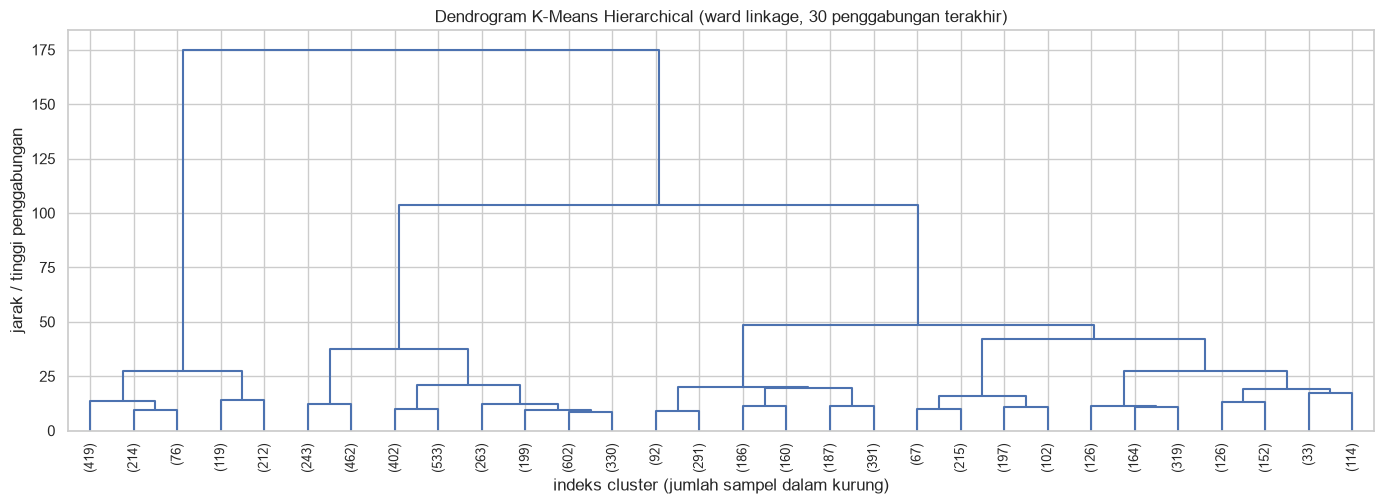

Tinggi penggabungan terakhir: 27.48 -> 37.54 -> 42.31 -> 48.41 -> 103.70 -> 175.13
Celah terbesar ada di antara tinggi 48.41 dan 103.70
Potongan di antara keduanya (mis. tinggi 70) menghasilkan 3 cluster,
sedangkan potongan antara 103.7 dan 175.1 (mis. tinggi 140) menghasilkan 2 cluster.


In [21]:
# Tampilkan dendrogram dari linkage matrix di atas.
# Batasi tampilan agar mudah dibaca (misalnya truncate_mode='lastp' atau p=30).
# Amati pada ketinggian berapa sebaiknya dendrogram dipotong untuk menentukan jumlah cluster.

plt.figure(figsize=(14, 5.2))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=9,
           show_leaf_counts=True, color_threshold=0)
plt.title("Dendrogram K-Means Hierarchical (ward linkage, 30 penggabungan terakhir)")
plt.xlabel("indeks cluster (jumlah sampel dalam kurung)")
plt.ylabel("jarak / tinggi penggabungan")
plt.tight_layout()
plt.show()

h_last = Z[-6:, 2]
print("Tinggi penggabungan terakhir:", " -> ".join(f"{h:.2f}" for h in h_last))
print("Celah terbesar ada di antara tinggi %.2f dan %.2f" % (h_last[-3], h_last[-2]))
print("Potongan di antara keduanya (mis. tinggi 70) menghasilkan 3 cluster,")
print("sedangkan potongan antara %.1f dan %.1f (mis. tinggi 140) menghasilkan 2 cluster." % (h_last[-2], h_last[-1]))


## 4.2 Perbandingan Metode Linkage

Linkage menentukan cara jarak antar cluster dihitung. Pada bagian ini kalian akan membandingkan empat metode linkage: ward, complete, average, dan single.

In [22]:
# Latih AgglomerativeClustering dengan masing-masing linkage (ward, complete, average, single).
# Gunakan jumlah cluster yang sama untuk semua linkage agar perbandingan adil.

linkage_methods = ["ward", "complete", "average", "single"]

hc_models = {}
for m in linkage_methods:
    hc = AgglomerativeClustering(n_clusters=K_FINAL, linkage=m)
    hc_models[m] = hc.fit(X_log_scaled)
    print(f"AgglomerativeClustering (linkage={m}, n_clusters={K_FINAL}) selesai dilatih")


AgglomerativeClustering (linkage=ward, n_clusters=2) selesai dilatih


AgglomerativeClustering (linkage=complete, n_clusters=2) selesai dilatih


AgglomerativeClustering (linkage=average, n_clusters=2) selesai dilatih


AgglomerativeClustering (linkage=single, n_clusters=2) selesai dilatih


In [23]:
# Hitung Silhouette Score untuk setiap linkage dan tampilkan jumlah anggota tiap cluster.
# Sajikan dalam satu tabel perbandingan.
# Amati apakah ada linkage yang menghasilkan cluster sangat tidak seimbang (misalnya satu cluster sangat besar dan lainnya hanya beberapa titik).

baris = []
for m, hc in hc_models.items():
    labels = hc.labels_
    ukuran = np.bincount(labels)
    baris.append({
        "linkage": m,
        "Silhouette": round(metrics.silhouette_score(X_log_scaled, labels), 4),
        "ukuran cluster": " / ".join(str(u) for u in ukuran),
        "cluster terkecil": int(ukuran.min()),
        "cluster terbesar": int(ukuran.max()),
        "seimbang?": "ya" if ukuran.min() / ukuran.max() > 0.1 else "TIDAK",
    })
link_cmp = pd.DataFrame(baris).sort_values("Silhouette", ascending=False).reset_index(drop=True)
print(link_cmp.to_string(index=False))

print("\nLinkage dengan Silhouette tertinggi:", link_cmp.loc[0, "linkage"])


 linkage  Silhouette ukuran cluster  cluster terkecil  cluster terbesar seimbang?
    ward      0.5951    5956 / 1040              1040              5956        ya
 average      0.5922    1232 / 5764              1232              5764        ya
complete      0.5057     6536 / 460               460              6536     TIDAK
  single      0.3877       6995 / 1                 1              6995     TIDAK

Linkage dengan Silhouette tertinggi: ward


**Pilihan linkage untuk Hierarchical Clustering:** **ward**

Alasan singkat: pada jumlah cluster yang sama (k = 2), **ward** memberikan Silhouette Score tertinggi (**0,5951**), diikuti average (0,5922), complete (0,5057), dan single (0,3877). Selain skornya paling tinggi, ward juga menghasilkan ukuran cluster yang masih seimbang dan masuk akal (5.956 vs 1.040) karena ward meminimalkan penambahan varians dalam cluster (variance minimization), sehingga cluster kompak tanpa terpecah oleh outlier. Sebaliknya single linkage menghasilkan 6.995 vs 1 (satu posting "menggantung" sendiri) akibat efek chaining, sehingga tidak layak dipakai.



## 4.3 Model Hierarchical Clustering Final

In [24]:
# Latih model AgglomerativeClustering final dengan linkage terbaik dan jumlah cluster yang sama dengan K-Means final.
# Simpan label cluster hasil prediksi untuk keperluan evaluasi.

HIER_LINKAGE = "ward"

hc_final = AgglomerativeClustering(n_clusters=K_FINAL, linkage=HIER_LINKAGE)
hier_labels = hc_final.fit_predict(X_log_scaled)

print("Hierarchical final: linkage =", HIER_LINKAGE, "| n_clusters =", K_FINAL)
print("Silhouette pada X_log_scaled:", round(metrics.silhouette_score(X_log_scaled, hier_labels), 4))
print("Jumlah anggota tiap cluster:", np.bincount(hier_labels))


Hierarchical final: linkage = ward | n_clusters = 2


Silhouette pada X_log_scaled: 0.5951
Jumlah anggota tiap cluster: [5956 1040]


In [25]:
# Buat profil setiap cluster pada data ASLI (sebelum transformasi log dan scaling): tampilkan median (dan rata-rata) tiap fitur per cluster beserta jumlah anggotanya.

profile_hc = df_feat.copy()
profile_hc["cluster"] = hier_labels

print("Profil cluster Hierarchical Clustering pada data ASLI (median):")
print(profile_hc.groupby("cluster")[features].median().round(1).to_string())
print("\nRata-rata per fitur (pelengkap):")
print(profile_hc.groupby("cluster")[features].mean().round(1).to_string())
print("\nJumlah anggota tiap cluster:")
print(profile_hc.groupby("cluster").size().rename("jumlah").to_string())


Profil cluster Hierarchical Clustering pada data ASLI (median):
         num_likes  num_comments  num_shares  num_emoji_reactions
cluster                                                          
0             38.0           2.0         0.0                  0.0
1            168.0         815.5       193.5                 60.5

Rata-rata per fitur (pelengkap):
         num_likes  num_comments  num_shares  num_emoji_reactions
cluster                                                          
0            198.3          15.3         2.7                  2.3
1            277.5        1430.2       255.4                 88.2

Jumlah anggota tiap cluster:
cluster
0    5956
1    1040


# 5. Evaluasi Model

In [26]:
# Hitung metrik evaluasi INTERNAL untuk K-Means dan Hierarchical Clustering:
# Silhouette Score (semakin tinggi semakin baik), Davies-Bouldin Index (semakin rendah semakin baik), dan Calinski-Harabasz Score (semakin tinggi semakin baik).
# Sajikan dalam satu tabel perbandingan.

eval_rows = {}
for nama, labels in {"K-Means": kmeans_labels, "Hierarchical": hier_labels}.items():
    eval_rows[nama] = {
        "n_clusters": len(np.unique(labels)),
        "Silhouette (tinggi = baik)": round(metrics.silhouette_score(X_log_scaled, labels), 4),
        "Davies-Bouldin (rendah = baik)": round(metrics.davies_bouldin_score(X_log_scaled, labels), 4),
        "Calinski-Harabasz (tinggi = baik)": round(metrics.calinski_harabasz_score(X_log_scaled, labels), 2),
        "ukuran cluster": " / ".join(str(u) for u in np.bincount(labels)),
    }
eval_df = pd.DataFrame(eval_rows).T
print("Metrik evaluasi INTERNAL (semua dihitung pada X_log_scaled):")
print(eval_df.to_string())


Metrik evaluasi INTERNAL (semua dihitung pada X_log_scaled):
             n_clusters Silhouette (tinggi = baik) Davies-Bouldin (rendah = baik) Calinski-Harabasz (tinggi = baik) ukuran cluster
K-Means               2                     0.5899                          0.605                           9897.49    5618 / 1378
Hierarchical          2                     0.5951                         0.4987                           8479.59    5956 / 1040


Varians yang dijelaskan: PC1 = 75.9%, PC2 = 16.0%, total = 91.8%


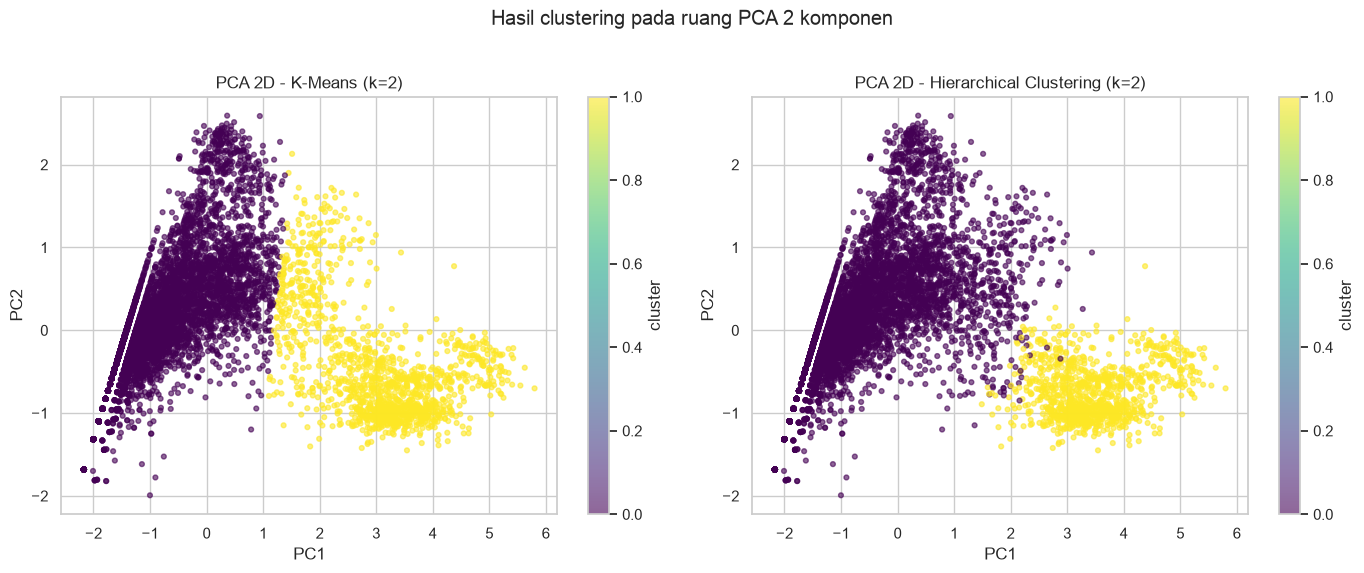

In [27]:
# Lakukan PCA ke 2 komponen pada X_log_scaled.
# Tampilkan scatter plot hasil clustering K-Means dan Hierarchical Clustering dalam satu baris subplot, diwarnai berdasarkan label cluster.
# Tampilkan juga persentase varians yang dijelaskan oleh kedua komponen PCA.

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_log_scaled)

var = 100 * pca.explained_variance_ratio_
print(f"Varians yang dijelaskan: PC1 = {var[0]:.1f}%, PC2 = {var[1]:.1f}%, total = {var.sum():.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.6))
for ax, labels, judul in zip(axes, [kmeans_labels, hier_labels],
                             ["K-Means", "Hierarchical Clustering"]):
    sc = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap="viridis", s=12, alpha=0.6)
    ax.set_title(f"PCA 2D - {judul} (k={len(np.unique(labels))})")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    plt.colorbar(sc, ax=ax, label="cluster")
plt.suptitle("Hasil clustering pada ruang PCA 2 komponen", y=1.02)
plt.tight_layout()
plt.show()


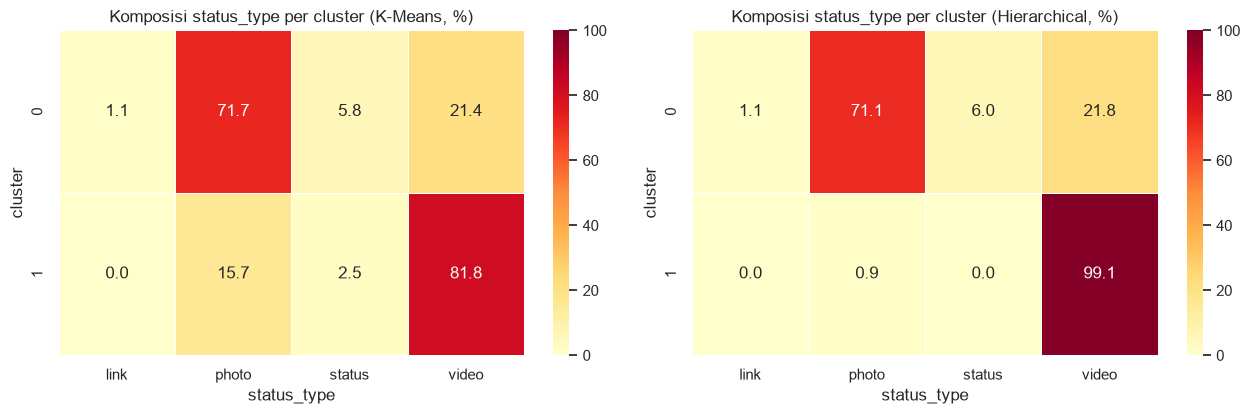

Komposisi status_type dalam persen (K-Means):
status_type  link  photo  status  video
K-Means                                
0             1.1   71.7     5.8   21.4
1             0.0   15.7     2.5   81.8

Komposisi status_type dalam persen (Hierarchical):
status_type   link  photo  status  video
Hierarchical                            
0              1.1   71.1     6.0   21.8
1              0.0    0.9     0.0   99.1


In [28]:
# Tampilkan komposisi status_type pada tiap cluster (crosstab dalam persen) untuk K-Means dan Hierarchical Clustering dalam bentuk heatmap.
# Susun keduanya dalam satu baris subplot.
# Ini hanya untuk membantu interpretasi cluster, bukan sebagai label asli.

comp = pd.DataFrame({"K-Means": kmeans_labels,
                     "Hierarchical": hier_labels,
                     "status_type": df_meta["status_type"].values})

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for ax, kolom in zip(axes, ["K-Means", "Hierarchical"]):
    ct = pd.crosstab(comp[kolom], comp["status_type"], normalize="index") * 100
    sns.heatmap(ct, annot=True, fmt=".1f", cmap="YlOrRd", ax=ax, vmin=0, vmax=100,
                linewidths=0.5)
    ax.set_title(f"Komposisi status_type per cluster ({kolom}, %)")
    ax.set_xlabel("status_type")
    ax.set_ylabel("cluster")
plt.tight_layout()
plt.show()

print("Komposisi status_type dalam persen (K-Means):")
print((pd.crosstab(comp["K-Means"], comp["status_type"], normalize="index") * 100).round(1).to_string())
print("\nKomposisi status_type dalam persen (Hierarchical):")
print((pd.crosstab(comp["Hierarchical"], comp["status_type"], normalize="index") * 100).round(1).to_string())


# 6. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan.

Beberapa hal yang perlu dibahas:
- Jelaskan pengaruh transformasi log dan feature scaling pada K-Means berdasarkan hasil pada bagian 3.1. Mengapa keduanya penting pada algoritma berbasis jarak, terutama untuk data yang sangat miring dan mengandung outlier ekstrem?
- Bagaimana kalian menangani kolom yang redundan atau banyak bernilai nol (misalnya reaksi emoji)? Jelaskan alasan pemilihan fitur kalian.
- Berapa jumlah cluster optimal menurut Elbow Method dan Silhouette Score? Apakah keduanya menghasilkan kesimpulan yang sama? Jika berbeda, mana yang kalian pilih dan mengapa?
- Bandingkan hasil keempat metode linkage pada Hierarchical Clustering. Linkage mana yang paling baik dan mengapa? Bagaimana karakteristik cluster yang dihasilkan oleh single linkage?
- Bandingkan performa K-Means vs Hierarchical Clustering berdasarkan metrik internal dan visualisasi PCA. Apakah hasilnya berbeda signifikan? Menurut kalian, kenapa demikian?
- Bagaimana karakteristik tiap cluster berdasarkan profil median fitur dan komposisi status_type? Beri nama atau julukan yang menggambarkan tiap cluster.
- Apa kelebihan dan kekurangan masing-masing metode (misalnya dari sisi kebutuhan menentukan k di awal, bentuk cluster, dan kebutuhan waktu serta memori)?

Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan, bukan hasil orang lain.

---

### Hasil Analisis

**1. Pengaruh transformasi log dan feature scaling pada K-Means (bagian 3.1)**

Pada data mentah tanpa scaling (`X_raw`), proporsi varians antar fitur sangat timpang: `num_comments` menyumbang **78,9%** varians, `num_likes` 19,1%, `num_shares` 1,7%, dan `num_emoji_reactions` hanya 0,2% (rasio std terbesar/terkecil antar fitur terpilih = 18,6 kali; terhadap seluruh fitur hitungan asli rasionya mencapai 1.224 kali). Skala `num_comments` juga sangat miring (skew 8,99, maksimum 20.990 sementara median hanya 4). Karena jarak Euclidean "dikuasai" fitur berskala besar, K-Means k=3 pada `X_raw` hanya menghasilkan cluster timpang **[6392, 137, 467]** - praktis memisahkan segelintir posting dengan komentar ekstrem dari sisanya - dengan Silhouette (diukur pada ruang `X_log_scaled` agar adil) hanya **0,2731**.

`X_raw_scaled` (scaling tanpa log) memang menyamakan skala antar fitur, tetapi skew dan outlier ekstrem tetap ada; K-Means memakai mean sebagai centroid sehingga pusat cluster masih tertarik ke ekor distribusi. Hasilnya tetap timpang **[373, 6277, 346]** dengan Silhouette **0,2533** (bahkan sedikit lebih rendah dari data mentah).

Transformasi `log1p` menekan ekor dan menurunkan skew drastis: `num_likes` 3,93 -> -0,01, `num_comments` 8,99 -> 1,05, `num_shares` 7,07 -> 1,53, `num_emoji_reactions` 6,97 -> 1,31. Ditambah `StandardScaler` (mean ~0, std = 1 pada tiap fitur), sebaran menjadi jauh lebih bulat dan seragam. Hasilnya cluster jauh lebih seimbang **[1131, 2258, 3607]** dan Silhouette melonjak ke **0,4638** (naik sekitar 70% dibanding kedua versi lainnya).

Keduanya penting karena K-Means dan Hierarchical Clustering berbasis jarak: tanpa scaling, fitur bersatuan besar selalu menentukan hasil; tanpa transformasi log, beberapa titik outlier yang sangat jauh mendominasi perhitungan jarak dan menarik centroid sehingga bentuk cluster tidak bulat dan hasil clustering menjadi tidak seimbang.

**2. Penanganan kolom redundan / banyak bernilai nol**

- `num_reactions` dibuang karena redundan: hampir tepat sama dengan `num_likes` + jumlah reaksi emoji (selisih maksimum 4, korelasi 0,995 dengan `num_likes`).
- Lima kolom emoji (60%-94% nol, 56,1% posting bernilai nol seluruhnya) digabung menjadi satu `num_emoji_reactions`, sehingga fitur emoji tetap terwakili tanpa membanjiri jarak dengan kolom hampir selalu nol.
- `status_id` (identifier), `status_type`/`status_published` (hanya interpretasi), dan `Column1`-`Column4` (kosong) dihapus.
- Nilai 0 dibiarkan karena bukan missing value; outlier ekstrem tidak dibuang (dikendalikan lewat log1p + scaling).
- Hasil akhir 4 fitur: `num_likes`, `num_comments`, `num_shares`, `num_emoji_reactions` - sesuai definisi tugas dan seluruhnya numerik.

**3. Jumlah cluster optimal menurut Elbow Method dan Silhouette Score**

- Elbow Method: penurunan inertia paling tajam di k = 2 -> 3 (-41,5%), lalu melandai (-16,2% di k=4, -16,5% di k=5, dan seterusnya); `KneeLocator` menandai siku di **k = 4**.
- Silhouette Score: tertinggi di **k = 2 (0,5899)**, turun ke 0,4638 (k=3) dan 0,3372 (k=4), lalu berfluktuasi di kisaran 0,31-0,36 tanpa pernah melebihi nilai pada k=2.

Keduanya **tidak menghasilkan kesimpulan yang sama**. Yang dipilih adalah **k = 2**, karena silhouette tidak pernah lebih baik pada k mana pun sehingga menambah cluster hanya memecah cluster besar / memisahkan outlier tanpa memperbaiki kualitas pemisahan; k=2 juga paling mudah diinterpretasikan, ukurannya tetap masuk akal (5.618 vs 1.378), sejalan dengan potongan dendrogram (celah tinggi 103,70-175,13), dan konsisten dengan hasil Hierarchical Clustering.

**4. Perbandingan keempat metode linkage (k = 2)**

| linkage | Silhouette | ukuran cluster |
|---------|-----------|----------------|
| ward | **0,5951** | 5.956 / 1.040 |
| average | 0,5922 | 1.232 / 5.764 |
| complete | 0,5057 | 6.536 / 460 |
| single | 0,3877 | 6.995 / **1** |

**Ward paling baik** karena meminimalkan penambahan varians intra-cluster sehingga cluster kompak, seimbang, dan tetap masuk akal ukurannya; average hampir setara (0,5922) tetapi lebih timpang; complete lebih rendah karena memakai jarak maksimum sehingga cluster hanya rapat di sekitar titik pusatnya dan tetap timpang (6.536 vs 460).

Karakteristik **single linkage** sangat khas: efek **chaining** (rantai). Titik-titik yang saling berdekatan secara berurutan dihubungkan menjadi satu cluster raksasa, sehingga menghasilkan **[6995, 1]** - satu posting outlier benar-benar menjadi cluster sendiri, Silhouette terburuk (0,3877), dan sangat tidak seimbang.

**5. K-Means vs Hierarchical Clustering**

| model | Silhouette | Davies-Bouldin | Calinski-Harabasz | ukuran cluster |
|-------|-----------|----------------|-------------------|----------------|
| K-Means (k=2) | 0,5899 | 0,6050 | **9897,49** | 5.618 / 1.378 |
| Hierarchical ward (k=2) | **0,5951** | **0,4987** | 8479,59 | 5.956 / 1.040 |

Hierarchical sedikit lebih baik pada Silhouette dan Davies-Bouldin (cluster lebih kompak dan terpisah), sedangkan K-Means lebih baik pada Calinski-Harabasz (yang menyukai pemisahan antar-varians yang seimbang, dan cluster K-Means memang lebih berimbang ukurannya). Perbedaan **tidak signifikan**: keduanya bekerja pada fitur dan ruang yang sama, dengan k yang sama, dan struktur PCA (PC1 75,9% + PC2 16,0% = **91,8%** varians terjelaskan) memperlihatkan hal yang sama - gugusan besar di sisi kiri (PC1 kecil) dan gugusan kecil terpisah di kanan. Pada plot, cluster 1 K-Means berada di PC1 1,10-5,80, sedangkan cluster 1 Hierarchical mulai dari PC1 1,49 - Hierarchical lebih "ketat" memilih inti posting viral (median komentar 815,5 vs 524 pada K-Means), itulah sebab Silhouette/DB-nya lebih baik tetapi ukuran clusternya lebih kecil sehingga CH-nya lebih rendah. Perbedaan muncul karena K-Means meminimalkan inertia dengan asumsi cluster bulat dan sebanding, sehingga menarik posting "menengah" ke cluster besar (5.618 vs 5.956), sementara ward menggabungkan berdasarkan kenaikan varians sehingga menghasilkan cluster inti yang lebih murni.

**6. Karakteristik tiap cluster (profil median + komposisi status_type)**

K-Means:
- **Cluster 0 - "Posting Sepi" (5.618 posting, 80,3%)**: median `num_likes` 33, `num_comments` 2, `num_shares` 0, `num_emoji_reactions` 0; komposisi 71,7% photo, 21,4% video, 5,8% status, 1,1% link. Posting rutin dengan interaksi minimum, didominasi foto.
- **Cluster 1 - "Video Viral" (1.378 posting, 19,7%)**: median `num_likes` 191, `num_comments` 524, `num_shares` 141,5, `num_emoji_reactions` 48; komposisi **81,8% video**, 15,7% photo. Engagement sangat tinggi dan didominasi video.

Hierarchical (ward):
- **Cluster 0 - "Posting Biasa / Rendah Engagement" (5.956 posting, 85,1%)**: median likes 38, comments 2, shares 0, emoji 0; 71,1% photo, 21,8% video.
- **Cluster 1 - "Video Viral Murni" (1.040 posting, 14,9%)**: median likes 168, comments 815,5, shares 193,5, emoji 60,5; **99,1% video**. Cluster paling ekstrem: hampir seluruh isinya video dengan komentar dan share sangat tinggi.

Kedua algoritma sepakat bahwa poros pemisah utama adalah **engagement rendah (mayoritas, berupa foto) vs engagement tinggi (minoritas, berupa video)**; Hierarchical hanya lebih selektif sehingga clusternya lebih kecil tetapi lebih murni.

**7. Kelebihan dan kekurangan masing-masing metode**

K-Means:
- Kelebihan: cepat dan hemat memori (kompleksitas mendekati O(n x k x iterasi)), mudah diskalakan, centroid mudah diinterpretasikan, hasil stabil bila `random_state` dan `n_init` tetap.
- Kekurangan: **wajib menentukan k di awal**, mengasumsikan cluster bulat dan sebanding ukurannya, sangat sensitif terhadap skala fitur dan outlier (terbukti pada bagian 3.1), dan hasilnya bisa berubah bila inisialisasi berubah.

Hierarchical Clustering:
- Kelebihan: **tidak perlu menentukan k di awal** (seluruh hierarki tersimpan di dendrogram, k dipilih saat memotong), bentuk cluster tidak dibatasi asumsi bulat, deterministik (tidak tergantung seed), dan langsung memperlihatkan hubungan antar cluster.
- Kekurangan: boros waktu dan memori O(n^2) - matriks jarak untuk 6.996 baris saja membutuhkan sekitar 200 MB dan linkage ward memakan waktu beberapa detik; tidak fleksibel untuk data baru (harus dihitung ulang dari awal); sangat bergantung pada pilihan linkage (single linkage menghasilkan cluster [6995, 1] yang tidak berguna).


# 7. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan.

Saran dapat berupa rekomendasi untuk eksperimen selanjutnya (misalnya melakukan clustering terpisah untuk periode sebelum dan sesudah tahun 2016, memanfaatkan fitur waktu seperti jam atau hari posting, mencoba algoritma clustering lain seperti DBSCAN atau Gaussian Mixture Model, melakukan reduksi dimensi sebelum clustering, atau mencoba variasi hyperparameter lain seperti n_init dan init pada K-Means), perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

---

### Kesimpulan

1. **Data**: 7.050 baris dan 16 kolom; `Column1`-`Column4` seluruhnya kosong dihapus, 54 baris duplikat (diabaikan `status_id`) dihapus, tersisa **6.996 baris** tanpa missing value. Tidak ada outlier yang dibuang.
2. **Fitur**: 4 fitur clustering - `num_likes`, `num_comments`, `num_shares`, `num_emoji_reactions` (5 kolom emoji digabung); `num_reactions` dibuang karena redundan; `status_type` hanya untuk interpretasi.
3. **Preprocessing berpengaruh besar**: K-Means k=3 pada data mentah/scaled-only memberi Silhouette 0,2731 / 0,2533 dengan cluster timpang, sedangkan setelah `log1p` + `StandardScaler` Silhouette naik ke 0,4638 dengan cluster jauh lebih seimbang.
4. **Jumlah cluster terbaik = 2**: Silhouette tertinggi 0,5899 di k=2 dan tidak pernah terlampaui pada k=2-10, walaupun Elbow/KneeLocator menunjukkan siku di k=3-4.
5. **Linkage terbaik = ward** (Silhouette 0,5951, ukuran 5.956/1.040); single linkage terburuk (0,3877, ukuran 6.995/1) karena efek chaining.
6. **Model akhir setara**: K-Means k=2 (Silhouette 0,5899; DB 0,6050; CH 9897,49) vs Hierarchical ward k=2 (Silhouette 0,5951; DB 0,4987; CH 8479,59). Hierarchical unggul tipis pada Silhouette dan Davies-Bouldin, K-Means unggul pada Calinski-Harabasz; visualisasi PCA (91,8% varians) menunjukkan struktur yang sama. Keduanya memisahkan posting **engagement rendah (mayoritas, foto)** dari **engagement tinggi (minoritas, hampir seluruhnya video)**.

### Saran

- Melakukan clustering terpisah untuk periode sebelum dan sesudah tahun 2016, karena kolom reaksi emoji bernilai 0 total sebelum fitur itu ada di Facebook sehingga pola cluster berbeda.
- Memanfaatkan fitur waktu dari `status_published` (jam posting, hari, akhir pekan atau bukan) sebagai tambahan fitur clustering.
- Mencoba algoritma clustering lain seperti DBSCAN (yang tidak membutuhkan k dan tahan terhadap outlier) atau Gaussian Mixture Model (yang memberi probabilitas keanggotaan cluster).
- Melakukan reduksi dimensi (PCA) sebelum clustering untuk melihat apakah struktur cluster lebih jelas dan waktu komputasi lebih hemat.
- Mencoba variasi hyperparameter K-Means lain seperti `n_init` dan `init` (mis. `k-means++` vs `random`) untuk menguji kestabilan hasil, serta metrik jarak lain (Manhattan, cosine) pada Hierarchical Clustering.
